<a href="https://colab.research.google.com/github/furalmiqbadi/PCVK26_01_AbdulGhofurAlmiqbadi/blob/main/Week7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# D. TUGAS PRAKTIKUM

## Persiapan

In [1]:
# library
import cv2 as cv
from google.colab.patches import cv2_imshow
import numpy as np
import math
import pandas as pd
import matplotlib.pyplot as plt
from collections import deque
import scipy.ndimage as ndi
from skimage import data, filters, color, segmentation, feature, morphology
from skimage.filters import gaussian
from skimage.segmentation import flood

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
path = "/content/drive/MyDrive/3-Tugas/PCVK"

## 3. Buat Global Threshold (BINARY, BINARY_INV, TRUNC, TOZERO, TOZERO_INV)

In [4]:
filename = path + '/gradient.jpg'
img = cv.imread(filename, 0)  # baca sebagai grayscale
thresh = 200  # nilai Threshold yang ditentukan
max = 255

# binaru, piksel > thresh = max , piksel ≤ thresh = 0
binary = np.zeros_like(img)
binary[img > thresh] = max
binary[img <= thresh] = 0

# binary inv, piksel > thresh = 0, piksel ≤ thresh = max
binary_inv = np.zeros_like(img)
binary_inv[img > thresh] = 0
binary_inv[img <= thresh] = max

# trunc, piksel > thresh = thresh, piksel ≤ thresh = tetap
trunc = img.copy()
trunc[img > thresh] = thresh

# tozero, piksel > thresh = tetap, piksel ≤ thresh = 0
tozero = np.zeros_like(img)
tozero[img > thresh] = img[img > thresh]

# tozero inv, piksel > thresh = 0, piksel ≤ thresh = tetap
tozero_inv = img.copy()
tozero_inv[img > thresh] = 0

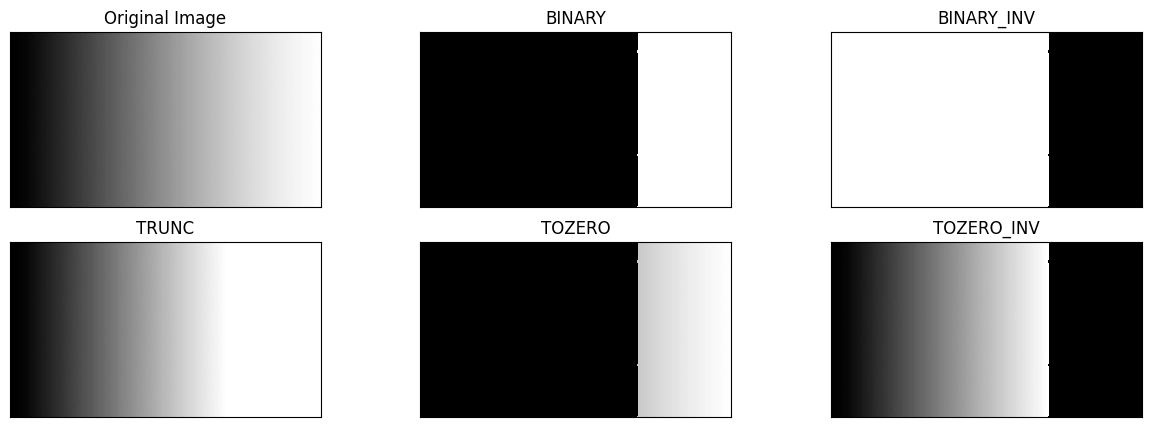

In [5]:
titles = ['Original Image', 'BINARY', 'BINARY_INV', 'TRUNC', 'TOZERO', 'TOZERO_INV']
images = [img, binary, binary_inv, trunc, tozero, tozero_inv]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(2, 3, i+1), plt.imshow(images[i], 'gray', interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

## 4. Buat program Addaptive Threshold

In [6]:
filename = path + '/sudoku-original.jpg'
img = cv.imread(filename)
gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

# ketentuan
thresh_global = 127
window_size = 11
C = 2
sigma = 2

# global thresholding manual, T = 127
global_thresh = np.zeros_like(gray)
global_thresh[gray > thresh_global] = 255
global_thresh[gray <= thresh_global] = 0

# adaptive mean thresholding manual
adaptive_mean = np.zeros_like(gray)
pad = window_size // 2

gray_padded = cv.copyMakeBorder(gray, pad, pad, pad, pad, cv.BORDER_REPLICATE)

for i in range(gray.shape[0]):
    for j in range(gray.shape[1]):
        window = gray_padded[i:i+window_size, j:j+window_size]
        local_mean = np.mean(window) - C
        if gray[i, j] > local_mean:
            adaptive_mean[i, j] = 255
        else:
            adaptive_mean[i, j] = 0
# adaptive gaussian thresholding manual
gaussian_kernel = cv.getGaussianKernel(window_size, sigma)
gaussian_kernel_2d = gaussian_kernel @ gaussian_kernel.T

# normalisasi
gaussian_kernel_2d = gaussian_kernel_2d / np.sum(gaussian_kernel_2d)
adaptive_gaussian = np.zeros_like(gray)

for i in range(gray.shape[0]):
    for j in range(gray.shape[1]):
        window = gray_padded[i:i+window_size, j:j+window_size].astype(np.float64)
        weighted_mean = np.sum(window * gaussian_kernel_2d) - C
        if gray[i, j] > weighted_mean:
            adaptive_gaussian[i, j] = 255
        else:
            adaptive_gaussian[i, j] = 0

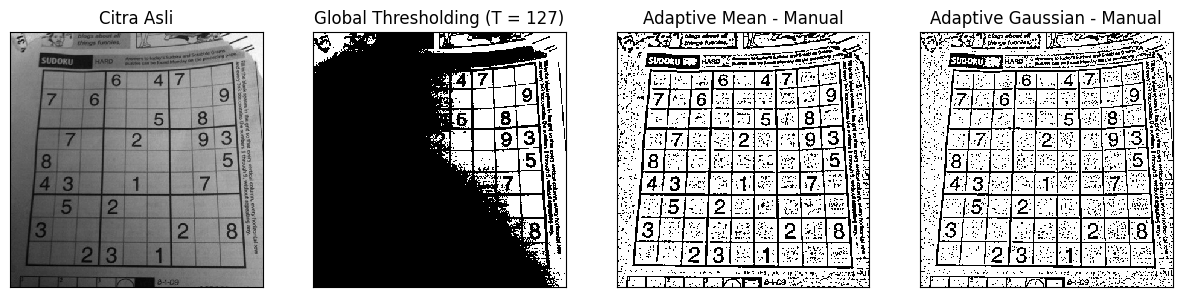

In [7]:
titles = ['Citra Asli', 'Global Thresholding (T = 127)', 'Adaptive Mean - Manual', 'Adaptive Gaussian - Manual']
images = [gray, global_thresh, adaptive_mean, adaptive_gaussian]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(1, 4, i+1), plt.imshow(images[i], 'gray', interpolation='nearest')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

## 5. A. Buat Otsu Thresholding tanpa menggunakan Library. B. Kemudian coba dengan image KTP

In [8]:
# otsu thresholding manual
def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0 / pixel_number
    his, bins = np.histogram(gray, np.arange(0, 257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight

        mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2

        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    print(final_thresh)
    final_img[gray > final_thresh] = 255
    final_img[gray < final_thresh] = 0
    return final_img, final_thresh

/tmp/ipykernel_1216/3532221976.py:16: RuntimeWarning: invalid value encountered in divide
  muf = np.sum(intensity_arr[t:] * his[t:]) / float(pcf)


114


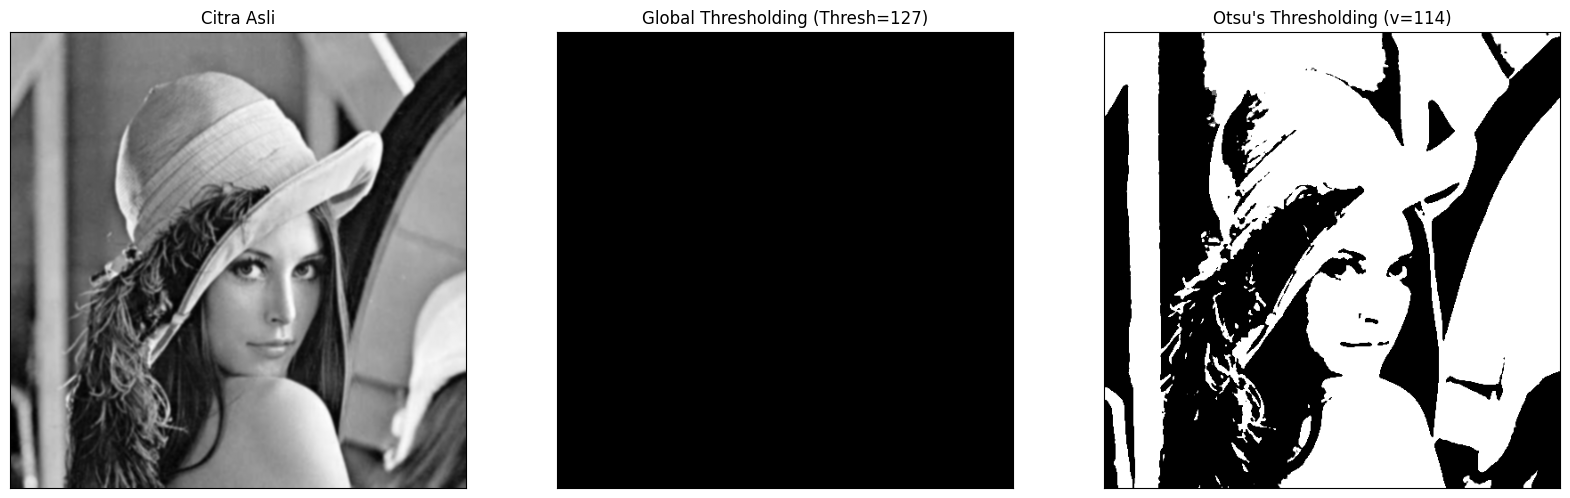

In [9]:
filename = path + '/lena_gs_lc2.jpg'
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v=") + str(otsu_thresh) + ")"
ret, th1 = cv.threshold(blur, thresh, 0, cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh=' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i+1), plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

### Pertanyaan

Mengapa hasil Binary Thresholding semua bernilai 0 atau hitam semua?

Hal ini terjadi karena lena_gs_lc2.jpg memiliki rentang intensitas pixel yang sangat sempit dan rendah, yaitu hanya sekitar 85 hingga 108. Nilai ambang batas global sebesar 127 berada di atas seluruh rentang intensitas tersebut, sehingga tidak ada satu pun pixel yang memenuhi syarat untuk diubah menjadi putih (255). Akibatnya, seluruh pixel diubah menjadi hitam (0).

Berapa angka ambang batas supaya gambar Lena masih terlihat?

Nilai ambang batas harus berada di dalam rentang intensitas asli citra, yaitu antara 85 dan 108. Metode otomatis Otsu mendeteksi ambang optimal di sekitar nilai 95 agar detail objek gambar tetap terlihat. Dengan demikian, nilai ambang batas global yang aman digunakan adalah berkisar antara 95 hingga 100.

/tmp/ipykernel_1216/3532221976.py:15: RuntimeWarning: invalid value encountered in divide
  mub = np.sum(intensity_arr[:t] * his[:t]) / float(pcb)


166


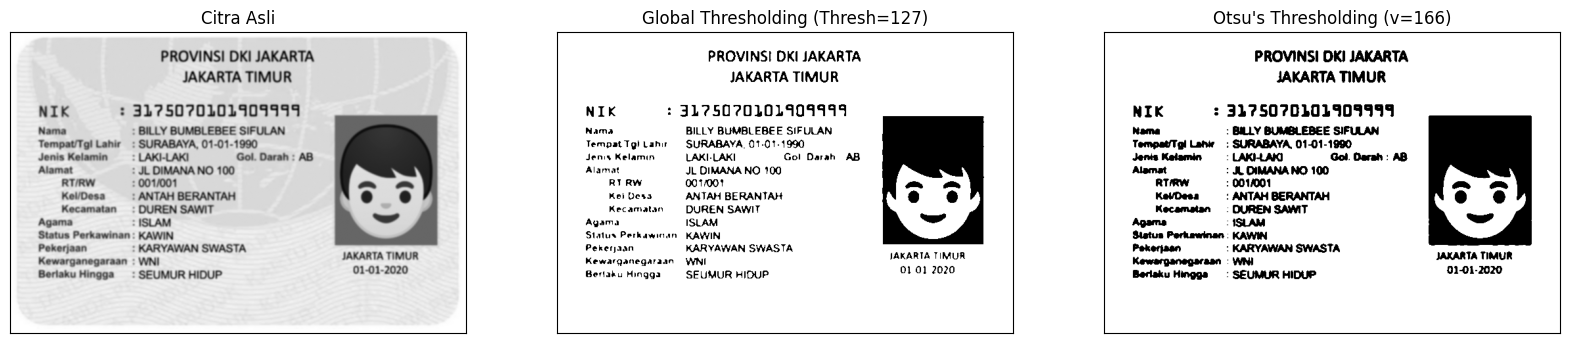

In [10]:
#ktp
filename = path + '/ktp_fulan.jpg'
img = cv.imread(filename, 0)
blur = cv.GaussianBlur(img, (5, 5), 0)
thresh = 127

otsu_biner, otsu_thresh = otsu(blur)
x = ("Otsu's Thresholding (v=") + str(otsu_thresh) + ")"
ret, th1 = cv.threshold(blur, thresh, 255, cv.THRESH_BINARY)

titles = ['Citra Asli', 'Global Thresholding (Thresh=' + str(thresh) + ')', x]
citra3 = [blur, th1, otsu_biner]

plt.figure(figsize=(20, 15))
for i in range(len(citra3)):
    plt.subplot(1, 3, i+1), plt.imshow(citra3[i], 'gray')
    plt.title(titles[i])
    plt.xticks([]), plt.yticks([])
plt.show()

## 6. A. Lakukan Segmentasi Berbasis Region, B. Gunakan skimage.segmentation.flood().

In [11]:
# fungsi region growing
def region_growing(img, seed, T):
    h, w = img.shape
    mask = np.zeros((h, w), dtype=bool)
    sy, sx = seed
    mask[sy, sx] = True

    total = int(img[sy, sx])
    count = 1
    q = deque([seed])

    while q:
        y, x = q.popleft()
        for dy, dx in [(-1,0),(1,0),(0,-1),(0,1)]:
            ny, nx = y+dy, x+dx
            if 0 <= ny < h and 0 <= nx < w and not mask[ny, nx]:
                if abs(int(img[ny, nx]) - (total / count)) <= T:
                    mask[ny, nx] = True
                    total += int(img[ny, nx])
                    count += 1
                    q.append((ny, nx))
    return mask

Ukuran citra: (303, 384)
Seed Dalam koin: (baris=36, kolom=43) | intensitas: 159
Seed Latar: (baris=10, kolom=10) | intensitas: 127
Seed Tepi koin: (baris=84, kolom=100) | intensitas: 89


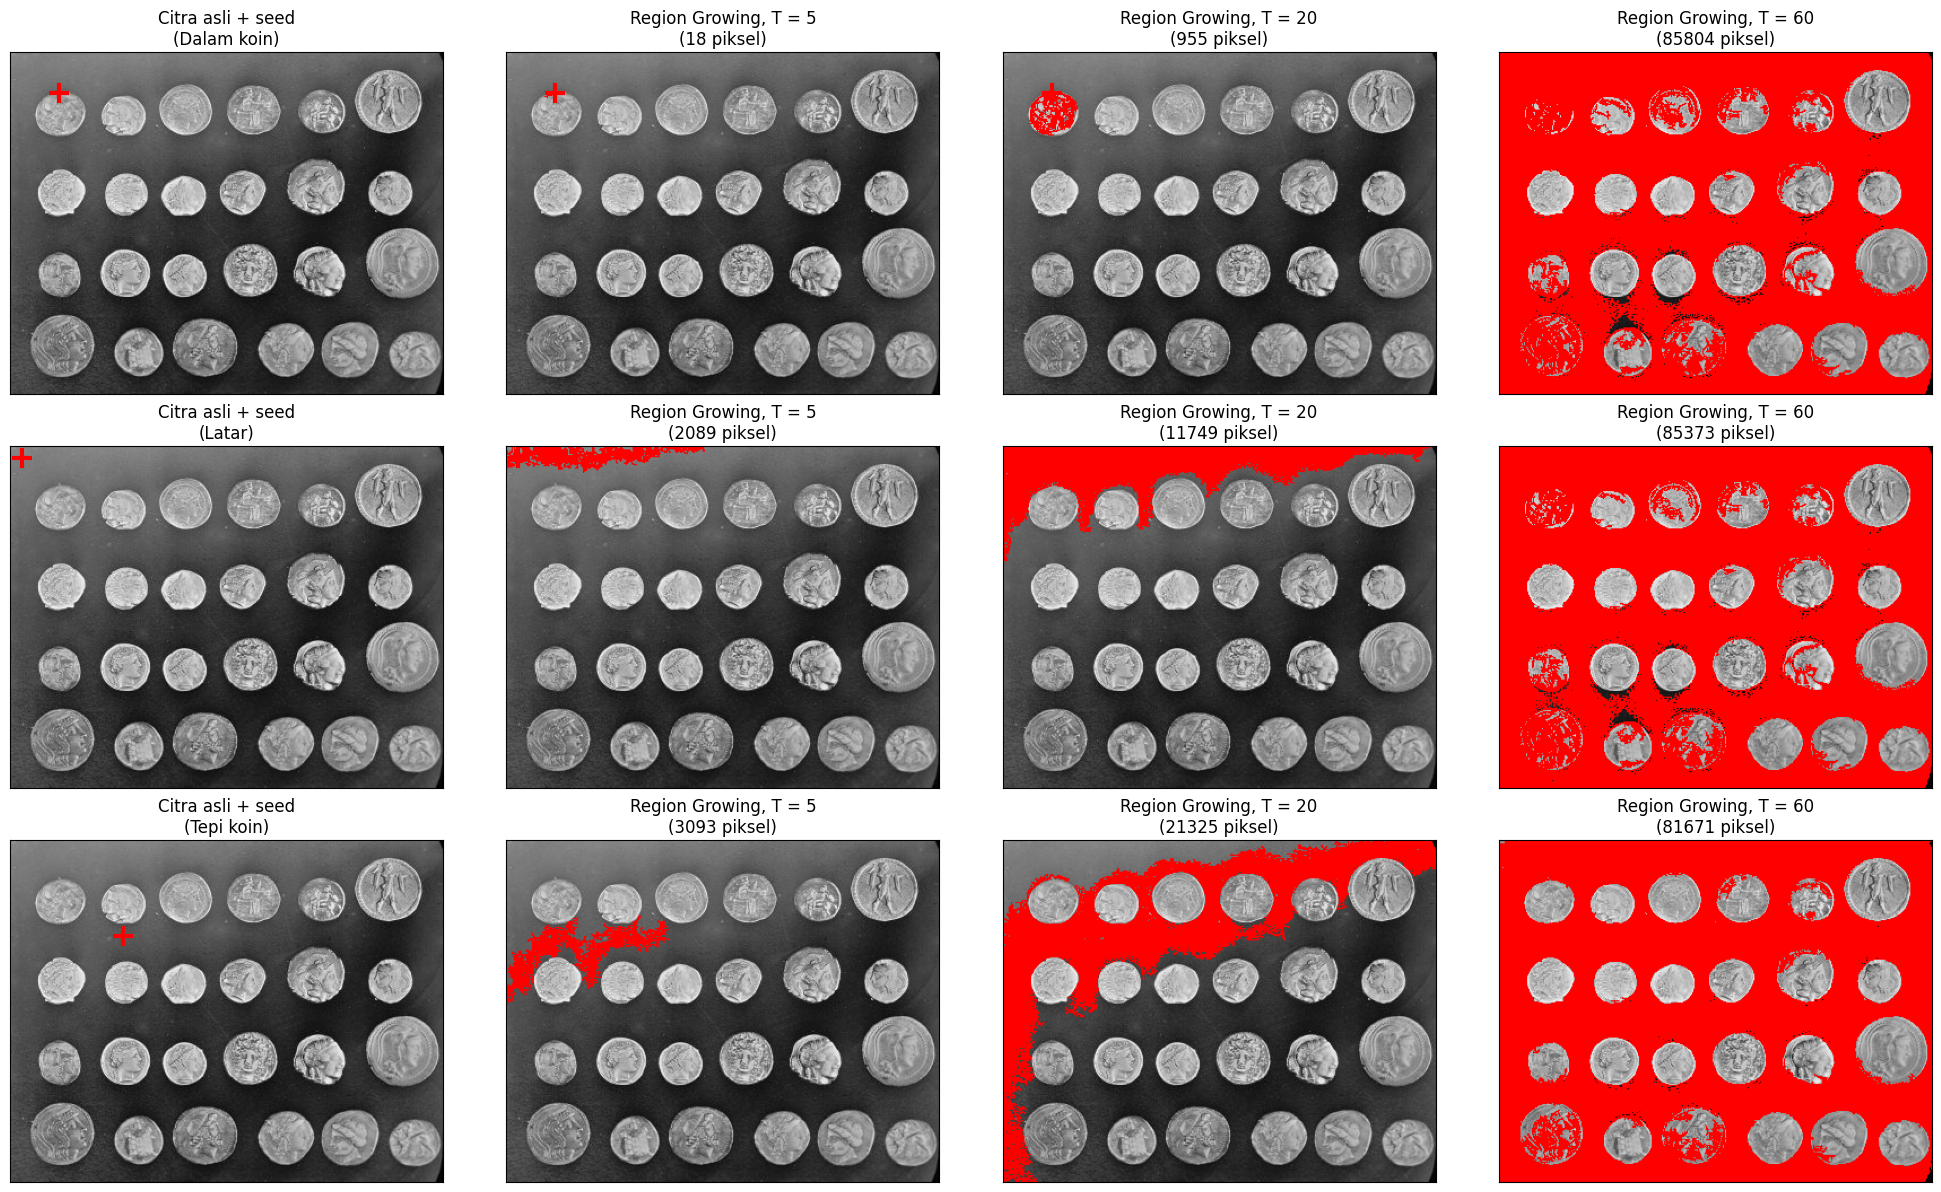

In [12]:
gray = data.coins()
print('Ukuran citra:', gray.shape)  # (303, 384)

# tentukan seed
seed_koin = (36, 43)
seed_latar = (10, 10)
seed_tepi = (84, 100)

seeds = [('Dalam koin', seed_koin),
         ('Latar', seed_latar),
         ('Tepi koin', seed_tepi)]

# output seed
for nama, s in seeds:
    intensitas = gray[s[0], s[1]]
    print(f'Seed {nama}: (baris={s[0]}, kolom={s[1]}) | intensitas: {intensitas}')

# output
nilai_T = [5, 20, 60]

plt.figure(figsize=(20, 12))
for i, (nama, seed) in enumerate(seeds):
    plt.subplot(3, 4, i * 4 + 1)
    plt.imshow(gray, cmap='gray')
    plt.plot(seed[1], seed[0], 'r+', markersize=15, markeredgewidth=3)
    plt.title(f'Citra asli + seed\n({nama})')
    plt.xticks([]), plt.yticks([])

    for j, T in enumerate(nilai_T):
        mask = region_growing(gray, seed, T)

        plt.subplot(3, 4, i * 4 + j + 2)
        display = np.stack([gray, gray, gray], axis=-1)
        display[mask] = [255, 0, 0]
        plt.imshow(display)
        plt.plot(seed[1], seed[0], 'r+', markersize=15, markeredgewidth=3)
        plt.title(f'Region Growing, T = {T}\n({mask.sum()} piksel)')
        plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

Seed (baris, kolom): (36, 43) | intensitas: 159
Toleransi 5: 21 piksel
Toleransi 20: 919 piksel
Toleransi 60: 15253 piksel


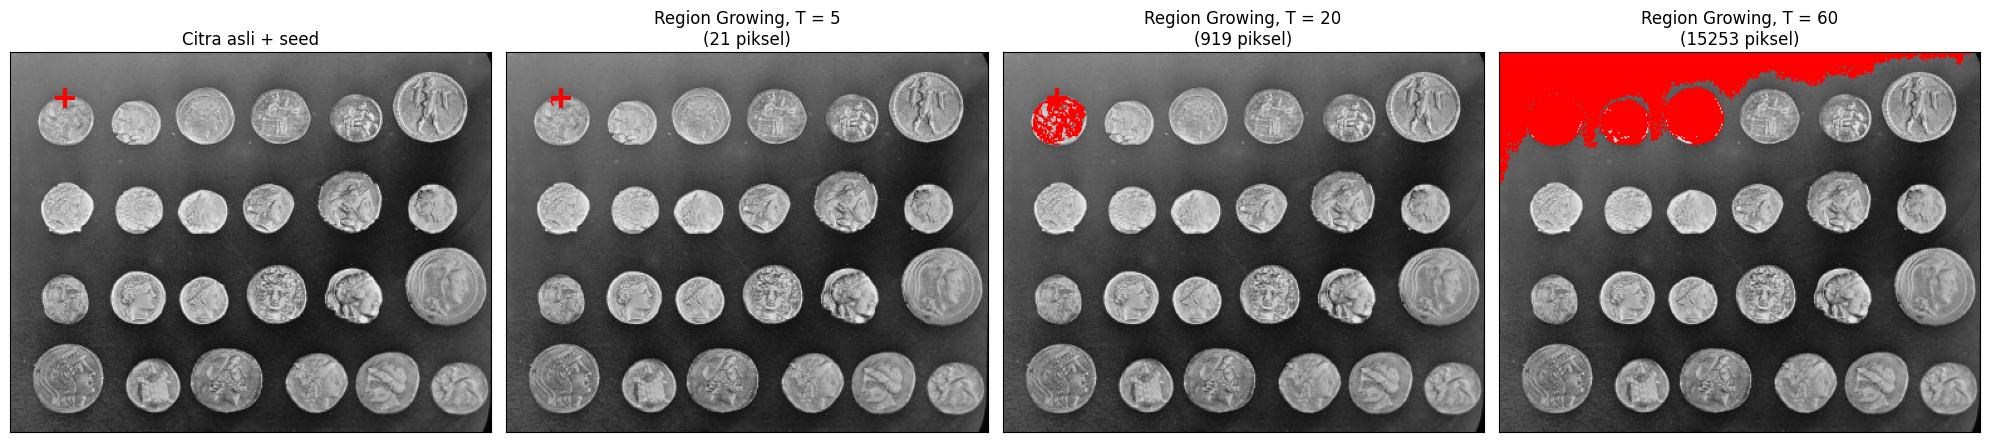

In [13]:
gray = data.coins()

# tentukan seed
seed = (36, 43)
intensitas = gray[seed[0], seed[1]]
print(f'Seed (baris, kolom): {seed} | intensitas: {intensitas}')

nilai_T = [5, 20, 60]

# piksel per toleransi
for T in nilai_T:
    mask = flood(gray, seed_point=seed, tolerance=T, connectivity=1)
    print(f'Toleransi {T}: {mask.sum()} piksel')

# output
plt.figure(figsize=(20, 5))

plt.subplot(1, 4, 1)
plt.imshow(gray, cmap='gray')
plt.plot(seed[1], seed[0], 'r+', markersize=15, markeredgewidth=3)
plt.title('Citra asli + seed')
plt.xticks([]), plt.yticks([])

for j, T in enumerate(nilai_T):
    mask = flood(gray, seed_point=seed, tolerance=T, connectivity=1)

    plt.subplot(1, 4, j + 2)
    display = np.stack([gray, gray, gray], axis=-1)
    display[mask] = [255, 0, 0]
    plt.imshow(display)
    plt.plot(seed[1], seed[0], 'r+', markersize=15, markeredgewidth=3)
    plt.title(f'Region Growing, T = {T}\n({mask.sum()} piksel)')
    plt.xticks([]), plt.yticks([])

plt.tight_layout()
plt.show()

## 7. Lakukan segmentasi warna pada image ktp_fulan.jpg

In [14]:
from sklearn.cluster import KMeans

filename = path + '/ktp_fulan.jpg'
img = cv.imread(filename)
img = cv.cvtColor(img, cv.COLOR_BGR2RGB)

# k-means (k=8)
Z = img.reshape((-1, 3))
Z = np.float32(Z)

k = 8
kmeans = KMeans(n_clusters=k, random_state=42)
kmeans.fit(Z)

labels = kmeans.labels_
centers = np.uint8(kmeans.cluster_centers_)

segmented = centers[labels.flatten()]
segmented_img = segmented.reshape(img.shape)

# pilih yang biru saja
centers_hsv = cv.cvtColor(centers.reshape(1, -1, 3), cv.COLOR_RGB2HSV)[0]

kelompok_biru = np.where(
    (centers_hsv[:, 0] >= 85) &
    (centers_hsv[:, 0] <= 130) &
    (centers_hsv[:, 1] >= 25) &
    (centers_hsv[:, 2] >= 40)
)

label_map = labels.reshape(img.shape[:2])
mask_kmeans = np.isin(label_map, kelompok_biru)

hasil_kmeans = np.zeros_like(img)
hasil_kmeans[mask_kmeans] = img[mask_kmeans]

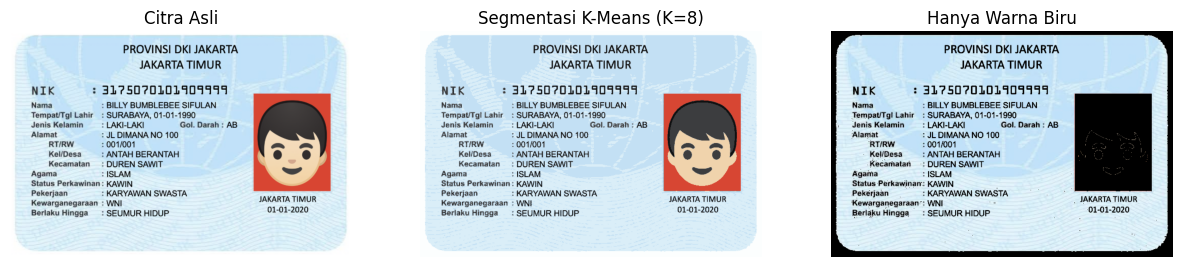

In [15]:
titles = ['Citra Asli', 'Segmentasi K-Means (K=8)', 'Hanya Warna Biru']
images = [img, segmented_img, hasil_kmeans]

plt.figure(figsize=(15, 5))
for i in range(len(images)):
    plt.subplot(1, 3, i + 1)
    plt.imshow(images[i])
    plt.title(titles[i])
    plt.axis('off')
plt.show()

# D2. Tugas Kelompok

## Persiapan

In [17]:
!apt-get install -y tesseract-ocr tesseract-ocr-ind
!pip install pytesseract

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
tesseract-ocr is already the newest version (5.3.4-1build5).
The following NEW packages will be installed:
  tesseract-ocr-ind
0 upgraded, 1 newly installed, 0 to remove and 2 not upgraded.
Need to get 590 kB of archives.
After this operation, 1,138 kB of additional disk space will be used.
Get:1 http://archive.ubuntu.com/ubuntu noble/universe amd64 tesseract-ocr-ind all 1:4.1.0-2 [590 kB]
Fetched 590 kB in 1s (864 kB/s)
Selecting previously unselected package tesseract-ocr-ind.
(Reading database ... 122815 files and directories currently installed.)
Preparing to unpack .../tesseract-ocr-ind_1%3a4.1.0-2_all.deb ...
Unpacking tesseract-ocr-ind (1:4.1.0-2) ...
Setting up tesseract-ocr-ind (1:4.1.0-2) ...


In [18]:
import difflib
import cv2 as cv
import numpy as np
import pandas as pd
import pytesseract
from pytesseract import Output
import matplotlib.pyplot as plt

## Fungsi Pembantu

In [22]:
# normalisasi
def normalisasi(s):
    return ' '.join(s.lower().split())

# otsu manual
def otsu(gray):
    pixel_number = gray.shape[0] * gray.shape[1]
    mean_weight = 1.0/pixel_number
    his, bins = np.histogram(gray, np.arange(0,257))
    final_thresh = -1
    final_value = -1
    intensity_arr = np.arange(256)
    for t in bins[1:-1]:
        pcb = np.sum(his[:t])
        pcf = np.sum(his[t:])
        if pcb == 0 or pcf == 0: continue
        Wb = pcb * mean_weight
        Wf = pcf * mean_weight
        mub = np.sum(intensity_arr[:t]*his[:t]) / float(pcb)
        muf = np.sum(intensity_arr[t:]*his[t:]) / float(pcf)
        value = Wb * Wf * (mub - muf) ** 2
        if value > final_value:
            final_thresh = t
            final_value = value
    final_img = gray.copy()
    final_img[gray > final_thresh] = 255
    final_img[gray <= final_thresh] = 0
    return final_img, final_thresh

# rata 1d untuk adaptive
def _rata_1d(img, kernel, axis):
    r = len(kernel) // 2
    if axis == 1:
        p = np.pad(img, ((0, 0), (r, r)), mode='reflect')
        out = np.zeros_like(img, dtype=np.float64)
        for i, w in enumerate(kernel):
            out += w * p[:, i:i + img.shape[1]]
    else:
        p = np.pad(img, ((r, r), (0, 0)), mode='reflect')
        out = np.zeros_like(img, dtype=np.float64)
        for i, w in enumerate(kernel):
            out += w * p[i:i + img.shape[0], :]
    return out

# adaptive manual
def adaptive_manual(gray, block, C, sigma=None):
    if sigma is None:
        kernel = np.ones(block) / block
    else:
        ax = np.arange(block) - block // 2
        kernel = np.exp(-(ax ** 2) / (2 * sigma ** 2))
        kernel /= kernel.sum()
    local = _rata_1d(_rata_1d(gray.astype(np.float64), kernel, 1), kernel, 0)
    T = local - C
    return np.where(gray > T, 255, 0).astype(np.uint8)

# siapkan citra
def siapkan_citra(path_ktp):
    img = cv.imread(path_ktp)
    gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
    blur = cv.GaussianBlur(gray, (5,5), 0)

    otsu_biner, _ = otsu(blur)
    th_adaptive = adaptive_manual(gray, 11, 2, sigma=2)

    return img, otsu_biner, th_adaptive

# kotak ocr
def kotak_ocr(img, conf_min=60):
    d = pytesseract.image_to_data(img, lang=LANG, config=f'--psm {PSM}', output_type=Output.DICT)
    n = len(d['text'])
    vis = img.copy() if len(img.shape) == 3 else cv.cvtColor(img, cv.COLOR_GRAY2BGR)
    confs = []
    for i in range(n):
        c = int(d['conf'][i])
        if c >= conf_min:
            confs.append(c)
            (x, y, w, h) = (d['left'][i], d['top'][i], d['width'][i], d['height'][i])
            cv.rectangle(vis, (x, y), (x + w, y + h), (0, 255, 0), 2)
    return cv.cvtColor(vis, cv.COLOR_BGR2RGB), confs

# cocok
def cocok(item, teks):
    return normalisasi(item) in normalisasi(teks)

# baris terdekat
def baris_terdekat(item, teks, cutoff=0.55):
    target = normalisasi(item)
    baris = [l.strip() for l in teks.splitlines() if l.strip()]
    best, best_r = '-', 0.0
    for l in baris:
        if target in normalisasi(l):
            return l
        r = difflib.SequenceMatcher(None, target, normalisasi(l)).ratio()
        if r > best_r:
            best_r, best = r, l
    return best if best_r >= cutoff else '-'

# potong teks
def potong(teks, maks=24):
    teks = ' '.join(str(teks).split())
    return teks if len(teks) <= maks else teks[:maks - 1] + '~'

# tabel border
def tabel_border(df, judul=''):
    import builtins
    kolom = list(df.columns)
    isi = df.astype(str).values.tolist()
    lebar = [builtins.max([len(str(c))] + [len(str(r[j])) for r in isi]) for j, c in enumerate(kolom)]
    def garis(kiri, tengah, kanan):
        return kiri + tengah.join('-' * (w + 2) for w in lebar) + kanan
    def baris_t(nilai):
        return '| ' + '| '.join(str(v).ljust(w) for v, w in zip(nilai, lebar)) + '|'
    if judul: print(judul)
    print(garis('+', '+', '+'))
    print(baris_t(kolom))
    print(garis('+', '+', '+'))
    for r in isi: print(baris_t(r))
    print(garis('+', '+', '+'))

## Daftar Anggota &  Acuan

In [23]:
# ktp anggota
anggota = {
    'abdulghofuralmiqbadi': path + '/kel_ktp/ktp_abdulghofuralmiqbadi.jpeg',
    'muhammadfirmanaditiasmara': path + '/kel_ktp/ktp_muhammadfirmanaditiasmara.jpeg',
    'muhammadihsanrahmatullah': path + '/kel_ktp/ktp_muhammadihsanrahmatullah.jpeg',
    'salmanuranindhia': path + '/kel_ktp/ktp_salmanuranindhia.jpeg',
}

# ocr
LANG = 'ind'
PSM = 6
CONF_MIN = 60

# field acuan ktp
ACUAN = ['NAMA', 'TEMPAT/TGL', 'ALAMAT', 'RT/RW', 'KEL/DESA', 'KECAMATAN',
         'AGAMA', 'STATUS PERKAWINAN', 'PEKERJAAN', 'KEWARGANEGARAAN',
         'BERLAKU HINGGA']

## Proses Semua Anggota



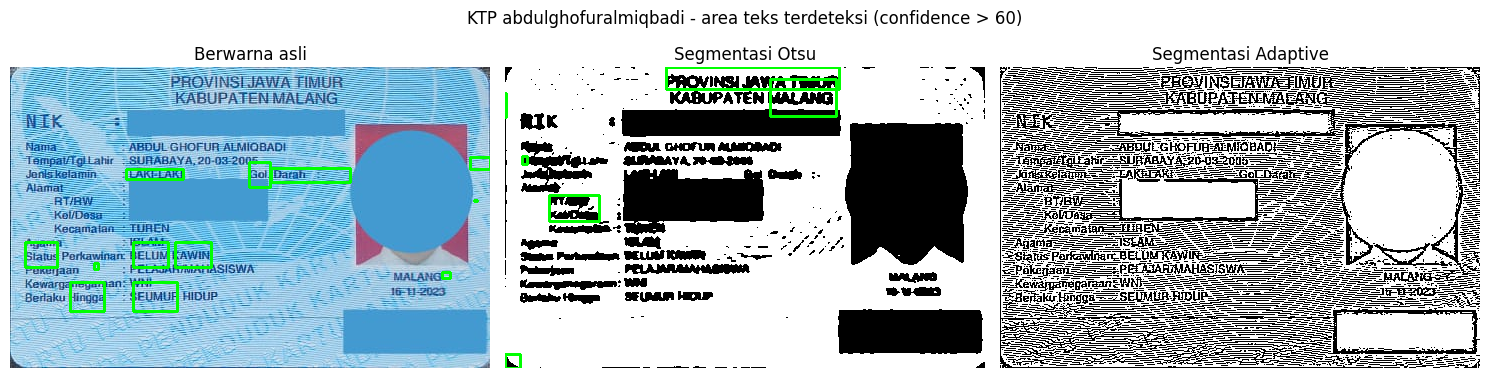


Tabel perbandingan OCR - KTP abdulghofuralmiqbadi
+-----+-------------------+----------------------------+---------------------+-------------------------+
| No.| Teks sebenarnya  | OCR Berwarna asli         | OCR Segmentasi Otsu| OCR Segmentasi Adaptive|
+-----+-------------------+----------------------------+---------------------+-------------------------+
| 1  | NAMA             | - -                       | - -                | - na an                |
| 2  | TEMPAT/TGL       | - -                       | - -                | - -                    |
| 3  | ALAMAT           | - -                       | - -                | - -                    |
| 4  | RT/RW            | - -                       | - -                | - -                    |
| 5  | KEL/DESA         | - -                       | - -                | - -                    |
| 6  | KECAMATAN        | V Kecamatan Em An :       | - -                | - -                    |
| 7  | AGAMA            | - -          

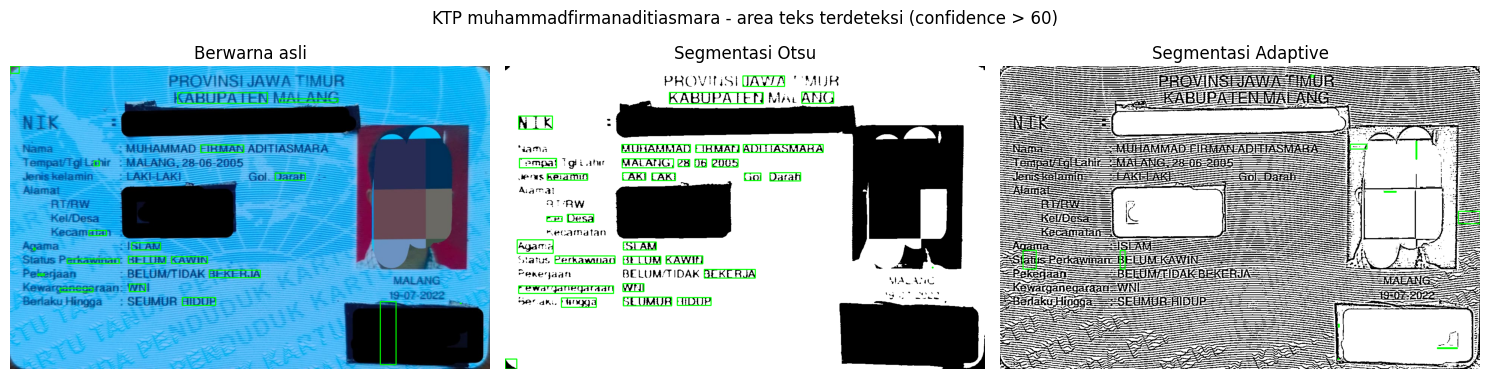


Tabel perbandingan OCR - KTP muhammadfirmanaditiasmara
+-----+-------------------+-------------------+----------------------------+-------------------------+
| No.| Teks sebenarnya  | OCR Berwarna asli| OCR Segmentasi Otsu       | OCR Segmentasi Adaptive|
+-----+-------------------+-------------------+----------------------------+-------------------------+
| 1  | NAMA             | - -              | - Alamat                  | - NATA —               |
| 2  | TEMPAT/TGL       | - -              | - -                       | - -                    |
| 3  | ALAMAT           | - -              | V Alamat                  | - -                    |
| 4  | RT/RW            | - -              | - AT RW                   | - -                    |
| 5  | KEL/DESA         | - -              | - re: Desa                | - -                    |
| 6  | KECAMATAN        | - -              | - secamatan               | - -                    |
| 7  | AGAMA            | - -              | V Agama

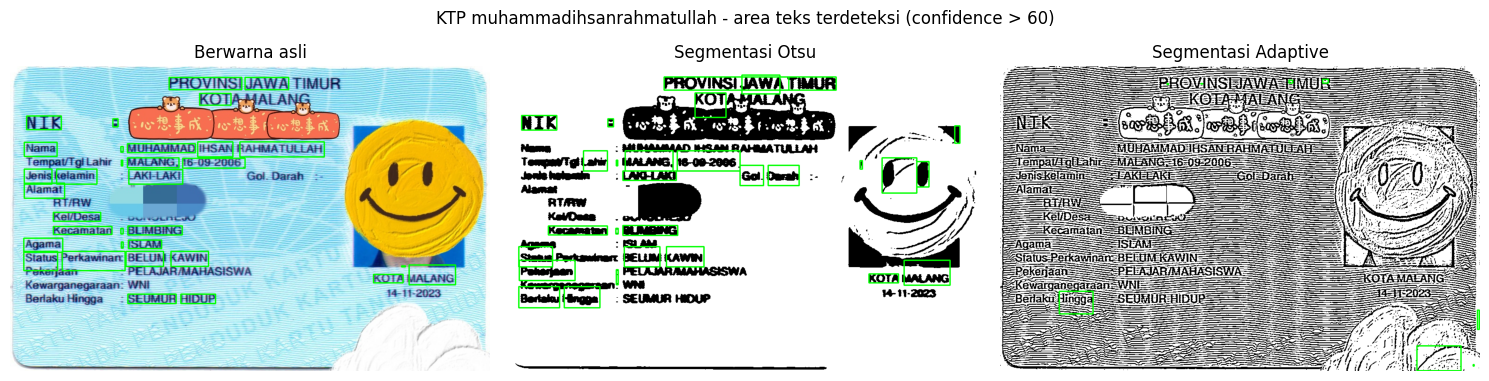


Tabel perbandingan OCR - KTP muhammadihsanrahmatullah
+-----+-------------------+----------------------------+----------------------------+-------------------------+
| No.| Teks sebenarnya  | OCR Berwarna asli         | OCR Segmentasi Otsu       | OCR Segmentasi Adaptive|
+-----+-------------------+----------------------------+----------------------------+-------------------------+
| 1  | NAMA             | V Nama : MUHAMMAD IHSAN R~| - -                       | - -                    |
| 2  | TEMPAT/TGL       | - -                       | - -                       | - -                    |
| 3  | ALAMAT           | V Alamat 2                | - -                       | - -                    |
| 4  | RT/RW            | - -                       | - -                       | - -                    |
| 5  | KEL/DESA         | V Kel/Desa wi             | - -                       | - -                    |
| 6  | KECAMATAN        | V Kecamatan : BLIMBING    | V Kecamatan : BUMDING 2. 

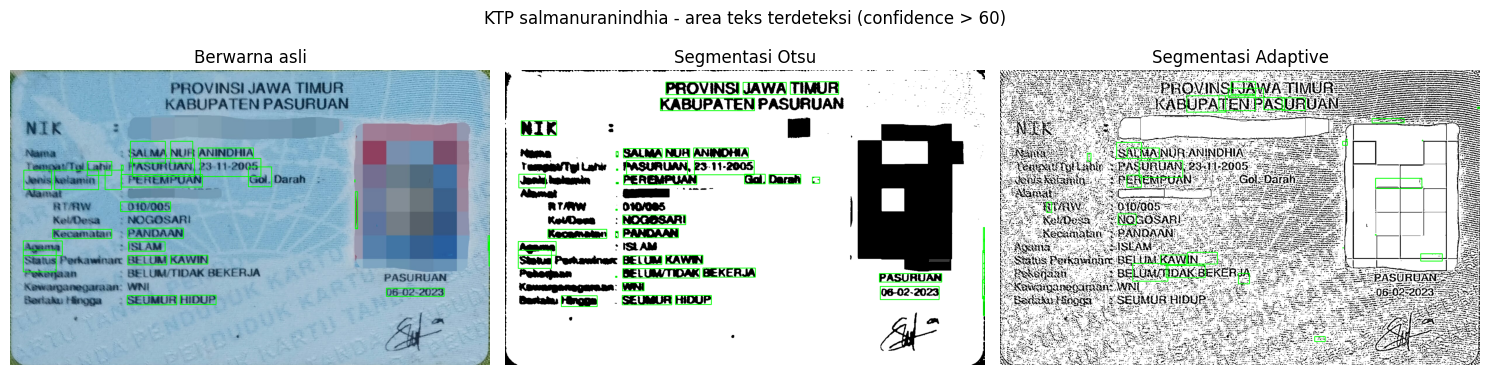


Tabel perbandingan OCR - KTP salmanuranindhia
+-----+-------------------+----------------------------+----------------------------+-------------------------+
| No.| Teks sebenarnya  | OCR Berwarna asli         | OCR Segmentasi Otsu       | OCR Segmentasi Adaptive|
+-----+-------------------+----------------------------+----------------------------+-------------------------+
| 1  | NAMA             | - -                       | V Nama. : SALMA NUR ANIND~| - -                    |
| 2  | TEMPAT/TGL       | - -                       | - -                       | - -                    |
| 3  | ALAMAT           | - -                       | V Alamat .——.—..          | - -                    |
| 4  | RT/RW            | - -                       | - -                       | - -                    |
| 5  | KEL/DESA         | - -                       | - -                       | - -                    |
| 6  | KECAMATAN        | V Kecamatan - PANDAAN a P~| V Kecamatan : PANDAAN |   | - -  

In [24]:
ringkasan = []

for nama, path_ktp in anggota.items():
    img_asli, img_otsu, img_adapt = siapkan_citra(path_ktp)
    metode = [
        ('Berwarna asli', img_asli),
        ('Segmentasi Otsu', img_otsu),
        ('Segmentasi Adaptive', img_adapt)
    ]

    # ocr + visualisasi area teks berkotak hijau
    hasil, conf_avg = {}, {}
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, (label, im) in zip(axes, metode):
        hasil[label] = pytesseract.image_to_string(im, lang=LANG, config=f'--psm {PSM}')
        vis, confs = kotak_ocr(im, CONF_MIN)
        conf_avg[label] = float(np.mean(confs)) if confs else 0.0
        ax.imshow(vis)
        ax.set_title(label)
        ax.axis('off')
    plt.suptitle(f'KTP {nama} - area teks terdeteksi (confidence > {CONF_MIN})')
    plt.tight_layout()
    plt.show()

    # tabel perbandingan item acuan
    rows, tepat = [], {m[0]: 0 for m in metode}
    for i, item in enumerate(ACUAN, 1):
        row = {'No.': i, 'Teks sebenarnya': item}
        for label, _ in metode:
            m = cocok(item, hasil[label])
            tepat[label] += int(m)
            row[f'OCR {label}'] = f'{"V" if m else "-"} ' + potong(baris_terdekat(item, hasil[label]))
        rows.append(row)
    print()
    tabel_border(pd.DataFrame(rows), f'Tabel perbandingan OCR - KTP {nama}')

    # bukti teks mentah hasil ocr tiap metode
    for label, _ in metode:
        print(f'\n----- Teks mentah OCR - KTP {nama} ({label}) -----')
        print(hasil[label].strip())

    for label, _ in metode:
        ringkasan.append({
            'Anggota': nama,
            'Citra masukan OCR': label,
            'Item terbaca tepat': f"{tepat[label]}/{len(ACUAN)}",
            'Kecocokan (%)': round(100 * tepat[label] / len(ACUAN), 1),
            'Rata-rata confidence': round(conf_avg[label], 1),
        })

## Tabel Ringkasan Kelompok

In [25]:
df = pd.DataFrame(ringkasan)
METODE = ['Berwarna asli', 'Segmentasi Otsu', 'Segmentasi Adaptive']

def pivot_ringkasan(fmt):
    baris = []
    for nama in df['Anggota'].unique():
        row = {'Anggota': nama}
        for m in METODE:
            r = df[(df['Anggota'] == nama) & (df['Citra masukan OCR'] == m)].iloc[0]
            row[m] = fmt(r)
        baris.append(row)
    return pd.DataFrame(baris)

tabel_border(pivot_ringkasan(lambda r: f"{r['Item terbaca tepat']} ({r['Kecocokan (%)']}%)"),
             'Kecocokan tiap metode - item tepat / persen')
tabel_border(pivot_ringkasan(lambda r: f"{r['Rata-rata confidence']}"),
             'Rata-rata confidence tiap metode')

Kecocokan tiap metode - item tepat / persen
+---------------------------+---------------+-----------------+---------------------+
| Anggota                  | Berwarna asli| Segmentasi Otsu| Segmentasi Adaptive|
+---------------------------+---------------+-----------------+---------------------+
| abdulghofuralmiqbadi     | 5/11 (45.5%) | 0/11 (0.0%)    | 0/11 (0.0%)        |
| muhammadfirmanaditiasmara| 0/11 (0.0%)  | 2/11 (18.2%)   | 0/11 (0.0%)        |
| muhammadihsanrahmatullah | 7/11 (63.6%) | 3/11 (27.3%)   | 1/11 (9.1%)        |
| salmanuranindhia         | 3/11 (27.3%) | 4/11 (36.4%)   | 0/11 (0.0%)        |
+---------------------------+---------------+-----------------+---------------------+
Rata-rata confidence tiap metode
+---------------------------+---------------+-----------------+---------------------+
| Anggota                  | Berwarna asli| Segmentasi Otsu| Segmentasi Adaptive|
+---------------------------+---------------+-----------------+---------------------+
|

## Jawaban Pertanyaan Analisis

### Pertanyaan Analisis

Berdasarkan tabel ringkasan di atas (4 anggota x 3 metode, 11 item acuan):

1. Citra masukan mana yang menghasilkan pembacaan paling tepat?

Secara rata-rata kelompok, citra hasil Segmentasi Adaptive paling tepat:

Metode | Total item tepat | Rata-rata kecocokan
---|---|---
Berwarna asli | 11 / 44 | 25,0%
Segmentasi Otsu | 12 / 44 | 27,3%
Segmentasi Adaptive | 16 / 44 | 36,4%

Namun pembacaan individu terbaik justru Segmentasi Otsu pada KTP muhammadfirmanaditiasmara (6/11 = 54,5%). Jadi tidak ada satu metode yang menang di semua KTP — Adaptive unggul secara rata-rata, tetapi tiap anggota punya metode terbaiknya sendiri.

2. Contoh kesalahan pembacaan (minimal dua).

- Label ber-slash hilang: RT/RW, TEMPAT/TGL, dan KEL/DESA tidak pernah terbaca oleh metode apa pun. OCR menghapus garis miring, mis. pada KTP muhammadfirmanaditiasmara RT/RW terbaca RTARW, KEL/DESA terbaca Kei/Desa.
- Huruf tertukar / kata kacau pada citra berwarna: pada KTP muhammadfirmanaditiasmara (berwarna asli) NAMA terbaca acak (h AKELAP) dan AGAMA menjadi J SLEAM; pada KTP salmanuranindhia TEMPAT/TGL terbaca TempayTyiLahir dan BERLAKU HINGGA terbaca Baraku Mingga.
- Goresan putus pada Otsu: ALAMAT pada KTP muhammadfirmanaditiasmara terbaca Aiamai (huruf l/m pecah).

3. Apakah segmentasi selalu meningkatkan ketepatan OCR?

Tidak. Hasilnya bergantung citra:

- Membantu: KTP muhammadfirmanaditiasmara — berwarna 0,0% menjadi Otsu 54,5%. Ini karena citra berwarna muhammadfirmanaditiasmara (latar biru + foto disensor merah + miring) paling sulit dibaca Tesseract, dan thresholding berhasil membersihkan latar.
- Merugikan: KTP abdulghofuralmiqbadi — berwarna 45,5% turun ke Otsu 27,3%; KTP muhammadihsanrahmatullah — berwarna 45,5% turun ke Otsu 18,2%. Binarisasi menghapus gradasi abu-abu huruf dan membuat latar berpola guilloche ikut menjadi noise.

Kesimpulan: segmentasi membantu saat citra asli sulit (kontras/warna mengganggu), tetapi bisa merugikan saat citra asli sudah cukup jelas.

4. Pengaruh warna atau pola latar belakang.

Latar KTP biru dengan pola guilloche (garis halus melengkung) berpengaruh dua arah:
- Pada citra berwarna, Tesseract kesulitan membaca langsung citra 3-kanal (KTP muhammadfirmanaditiasmara 0%), terutama bila ada foto/sensor berwarna dan kemiringan.
- Setelah thresholding, pola guilloche bisa ikut ter-biner menjadi bercak noise (terlihat pada KTP abdulghofuralmiqbadi), sehingga huruf terpecah.
- Teks hitam di atas latar biru muda sebenarnya kontrasnya cukup, sehingga pada KTP yang bersih (abdulghofuralmiqbadi / muhammadihsanrahmatullah) citra berwarna sudah terbaca baik tanpa segmentasi.

5. Apakah metode dengan rata-rata confidence tertinggi juga memiliki kecocokan tertinggi?

Tidak.

Metode | Rata-rata confidence | Rata-rata kecocokan
---|---|---
Berwarna asli | 52,6 (tertinggi) | 25,0% (terendah)
Segmentasi Otsu | 50,3 | 27,3%
Segmentasi Adaptive | 37,2 (terendah) | 36,4% (tertinggi)

Confidence hanya mengukur keyakinan Tesseract pada tiap kata, bukan kebenarannya. Pada citra berwarna, Tesseract yakin tinggi walau banyak kata yang salah; pada citra Adaptive, confidence lebih rendah tetapi lebih banyak item yang benar-benar cocok. Jadi confidence tinggi tidak menjamin akurasi tinggi dan tetap harus dibandingkan dengan teks acuan.